# 01 — Exploration des données MovieLens

**Objectif** : comprendre le jeu de données avant tout modèle — ce qu'il contient réellement,
sa qualité, et les propriétés (rareté, longue traîne, biais de notation) qui conditionneront
les choix de modélisation des sprints suivants.

Ce notebook ne contient pas de logique métier : tous les calculs viennent du paquet `recsys`
(`recsys.data.validation`, `recsys.analysis.eda`), testé par `pytest`. Les mêmes fonctions
produisent `reports/data_report.md`.

Prérequis : `python scripts/download_data.py`.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from recsys.analysis import eda, plots
from recsys.analysis.report import compute_statistics
from recsys.config import load_config
from recsys.data.loaders import load_raw_tables, read_header
from recsys.data.schemas import SCHEMAS
from recsys.data.validation import quality_report
from recsys.preprocessing import cleaning
from recsys.preprocessing.pipeline import clean_tables
from recsys.utils.seed import set_seed

%matplotlib inline
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 20)

config = load_config()
set_seed(config.project.seed)


def show(fig):
    """Affiche une figure une seule fois puis libère la mémoire."""
    display(fig)
    plt.close(fig)


print("Dataset :", config.dataset.name, "|", config.raw_dataset_dir)

Dataset : ml-25m | C:\cvp\recommender-system\data\raw\ml-25m


## 1. Fichiers réellement présents

On ne suppose aucune colonne : on lit l'en-tête de chaque fichier de l'archive.

In [2]:
files = pd.DataFrame(
    [
        {"fichier": p.name, "taille_Mo": p.stat().st_size / 1e6,
         "colonnes": read_header(p) if p.suffix == ".csv" else "-"}
        for p in sorted(config.raw_dataset_dir.iterdir())
    ]
)
pd.set_option("display.max_colwidth", 80)
files

,fichier,taille_Mo,colonnes
0,genome-scores.csv,435.164,"[movieId, tagId, relevance]"
1,genome-tags.csv,0.018,"[tagId, tag]"
2,links.csv,1.369,"[movieId, imdbId, tmdbId]"
3,movies.csv,3.038,"[movieId, title, genres]"
4,ratings.csv,678.261,"[userId, movieId, rating, timestamp]"
5,README.txt,0.010,-
6,tags.csv,38.810,"[userId, movieId, tag, timestamp]"


Le projet utilise les quatre tables décrites dans `recsys.data.schemas`. Le chargement vérifie
que les colonnes attendues existent (sinon `SchemaError`) et applique des types compacts.

In [3]:
raw = load_raw_tables(config.raw_dataset_dir)
for name, df in raw.items():
    print(f"\n=== {name} : {len(df):,} lignes x {df.shape[1]} colonnes "
          f"({df.memory_usage(deep=True).sum() / 1e6:,.0f} Mo en mémoire) ===")
    display(df.head(5))
    display(df.dtypes.rename("dtype").to_frame().T)


=== ratings : 25,000,095 lignes x 4 colonnes (500 Mo en mémoire) ===


,userId,movieId,rating,timestamp
0,1,296,5.000,1147880044
1,1,306,3.500,1147868817
2,1,307,5.000,1147868828
3,1,665,5.000,1147878820
4,1,899,3.500,1147868510


,userId,movieId,rating,timestamp
dtype,int32,int32,float32,int64



=== movies : 62,423 lignes x 3 colonnes (4 Mo en mémoire) ===


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,movieId,title,genres
dtype,int32,string,string


... (2 outputs left out)

,userId,movieId,tag,timestamp
dtype,int32,int32,string,int64



=== links : 62,423 lignes x 3 colonnes (2 Mo en mémoire) ===


,movieId,imdbId,tmdbId
0,1,0114709,862
1,2,0113497,8844
2,3,0113228,15602
3,4,0114885,31357
4,5,0113041,11862


,movieId,imdbId,tmdbId
dtype,int32,string,Int64


## 2. Qualité : valeurs manquantes, doublons, cohérence

In [4]:
prep = config.preprocessing
quality = quality_report(raw, prep.rating_min, prep.rating_max)

pd.DataFrame(
    [
        {"table": name, "lignes": info["n_rows"],
         "valeurs manquantes": sum(info["missing"].values()),
         "lignes dupliquées": info["duplicate_rows"],
         "doublons sur la clé": info["duplicate_keys"], "clé": ", ".join(info["key"])}
        for name, info in quality["tables"].items()
    ]
)

,table,lignes,valeurs manquantes,lignes dupliquées,doublons sur la clé,clé
0,ratings,25000095,0,0,0,"userId, movieId"
1,movies,62423,0,0,0,movieId
2,tags,1093360,16,0,0,"userId, movieId, tag"
3,links,62423,107,0,0,movieId


In [5]:
missing = pd.DataFrame({name: pd.Series(info["missing"]) for name, info in quality["tables"].items()})
missing.fillna("-")

C:\Users\DELL\AppData\Local\Temp\ipykernel_13844\4150717411.py:2: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  missing.fillna("-")


,ratings,movies,tags,links
genres,-,0.000,-,-
imdbId,-,-,-,0.000
movieId,0.000,0.000,0.000,0.000
rating,0.000,-,-,-
tag,-,-,16.000,-
timestamp,0.000,-,0.000,-
title,-,0.000,-,-
tmdbId,-,-,-,107.000
userId,0.000,-,0.000,-


In [6]:
print(json.dumps({k: quality[k] for k in ("ratings", "movies", "integrity")}, indent=2))

{
  "ratings": {
    "out_of_range": 0,
    "not_half_star": 0,
    "distinct_values": [
      0.5,
      1.0,
      1.5,
      2.0,
      2.5,
      3.0,
      3.5,
      4.0,
      4.5,
      5.0
    ],
    "non_positive_timestamps": 0,
    "first_rating": "1995-01-09T11:46:49+00:00",
    "last_rating": "2019-11-21T09:15:03+00:00"
  },
  "movies": {
    "no_genres_listed": 5062,
    "titles_without_year": 412,
    "duplicate_titles": 98
  },
  "integrity": {
    "rated_movies_missing_from_catalog": 0,
    "tagged_movies_missing_from_catalog": 0,
    "linked_movies_missing_from_catalog": 0,
    "catalog_movies_without_rating": 3376,
    "catalog_movies_without_tag": 17172,
    "catalog_movies_without_link": 0
  }
}


Regardons les cas particuliers repérés dans le catalogue : titres sans année, films sans genre,
titres portés par plusieurs `movieId`.

In [7]:
movies_raw = raw["movies"]
titles = movies_raw["title"].str.strip()
print("Titres sans année :")
display(movies_raw[~titles.str.contains(r"\(\d{4}\)\s*$")].head(8))
print("Films sans genre :")
display(movies_raw[movies_raw["genres"] == "(no genres listed)"].head(5))
print("Titres en double :")
display(movies_raw[titles.duplicated(keep=False)].sort_values("title").head(10))

Titres sans année :


,movieId,title,genres
15036,79607,"Millions Game, The (Das Millionenspiel)",Action|Drama|Sci-Fi|Thriller
18789,98063,Mona and the Time of Burning Love (Mona ja palavan rakkauden aika) (1983)),Drama
25387,123619,Terrible Joe Moran,(no genres listed)
26284,125571,The Court-Martial of Jackie Robinson,(no genres listed)
26309,125632,In Our Garden,(no genres listed)
26392,125958,Stephen Fry In America - New World,(no genres listed)
26576,126438,Two: The Story of Roman & Nyro,Documentary|Drama
26699,127005,A Year Along the Abandoned Road,(no genres listed)


Films sans genre :


,movieId,title,genres
15881,83773,Away with Words (San tiao ren) (1999),(no genres listed)
16060,84768,Glitterbug (1994),(no genres listed)
16351,86493,"Age of the Earth, The (A Idade da Terra) (1980)",(no genres listed)
16491,87061,Trails (Veredas) (1978),(no genres listed)
17404,91246,Milky Way (Tejút) (2007),(no genres listed)


Titres en double :


,movieId,title,genres
13713,71057,9 (2009),Adventure|Animation|Sci-Fi
61103,204982,9 (2009),Comedy
30628,136696,Absolution (2015),Action|Adventure|Crime|Thriller
37060,151797,Absolution (2015),Drama|Thriller
580,588,Aladdin (1992),Adventure|Animation|Children|Comedy|Musical
22286,114240,Aladdin (1992),Adventure|Animation|Children|Comedy|Fantasy
50683,181565,Alone (2017),Fantasy|Sci-Fi
58489,198719,Alone (2017),(no genres listed)
61714,206712,American Woman (2019),(no genres listed)
61913,207249,American Woman (2019),Drama


## 3. Nettoyage en mémoire

Pour la suite on travaille sur les tables nettoyées (détail et justification dans le notebook 02).

In [8]:
tables = clean_tables(raw, config)
del raw
stats = compute_statistics(tables, config)
pd.Series(stats["overview"]).to_frame("valeur")

,valeur
n_users,162541
n_movies_catalog,62423
n_movies_rated,59047
n_ratings,25000095
n_tags,1093333
density,0.003
mean_rating,3.534
median_rating,3.500
first_rating,1995-01-09 11:46:49+00:00
last_rating,2019-11-21 09:15:03+00:00


## 4. Distribution des notes

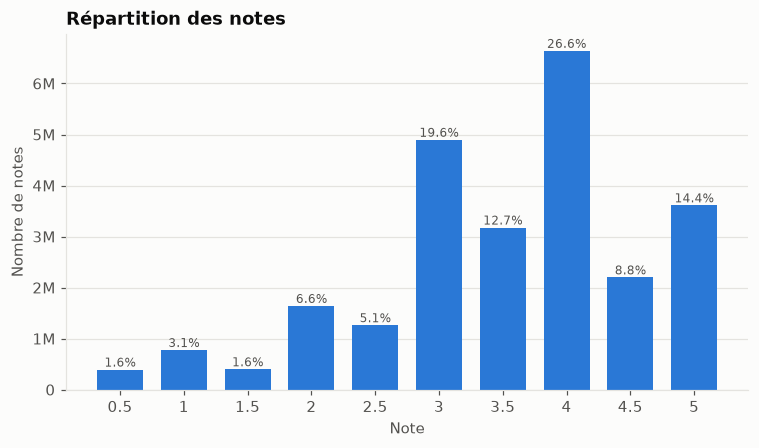

,rating,count,share
0,0.500,393068,0.016
1,1.000,776815,0.031
2,1.500,399490,0.016
3,2.000,1640868,0.066
4,2.500,1262797,0.051
5,3.000,4896928,0.196
6,3.500,3177318,0.127
7,4.000,6639798,0.266
8,4.500,2200539,0.088
9,5.000,3612474,0.144


In [9]:
show(plots.plot_rating_distribution(stats["rating_distribution"]))
stats["rating_distribution"]

In [10]:
dist = stats["rating_distribution"]
half = dist[dist["rating"] % 1 != 0]["share"].sum()
positive = dist[dist["rating"] >= 4]["share"].sum()
print(f"Part des demi-notes (x.5)   : {half:.1%}")
print(f"Part des notes >= 4         : {positive:.1%}")
print(f"Part des notes <= 2         : {dist[dist['rating'] <= 2]['share'].sum():.1%}")

Part des demi-notes (x.5)   : 29.7%
Part des notes >= 4         : 49.8%
Part des notes <= 2         : 12.8%


## 5. Comportement des utilisateurs

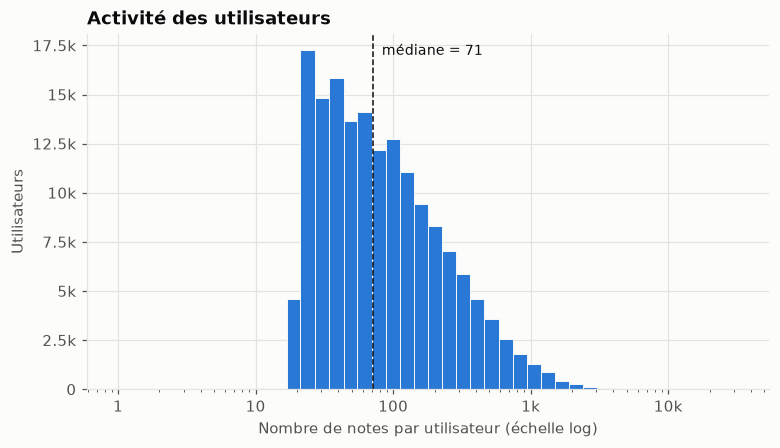

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
notes par utilisateur,"162,541.000",153.808,268.048,20.000,20.000,22.000,36.000,71.000,162.000,554.000,"1,228.000","32,202.000"


In [11]:
users = stats["users"]
show(plots.plot_count_histogram(users["n_ratings"], "utilisateur", "Activité des utilisateurs"))
eda.describe_counts(users["n_ratings"]).to_frame("notes par utilisateur").T

In [12]:
print("Utilisateurs ayant au plus n notes :")
display(stats["user_low"])
print("Part des notes déposée par les utilisateurs les plus actifs :")
display(stats["user_concentration"])

Utilisateurs ayant au plus n notes :


,max_ratings,n_entities,share_entities,share_ratings
0,1,0,0.000,0.000
1,5,0,0.000,0.000
2,10,0,0.000,0.000
3,20,4611,0.028,0.004
4,50,61467,0.378,0.079
5,100,99439,0.612,0.187


Part des notes déposée par les utilisateurs les plus actifs :


,top_share,n_entities,share_ratings
0,0.010,1625,0.121
1,0.050,8127,0.325
2,0.100,16254,0.468
3,0.200,32508,0.640


Chaque utilisateur a sa propre échelle : certains notent haut, d'autres bas. Cette dispersion
justifie de centrer les notes par utilisateur dans les modèles collaboratifs.

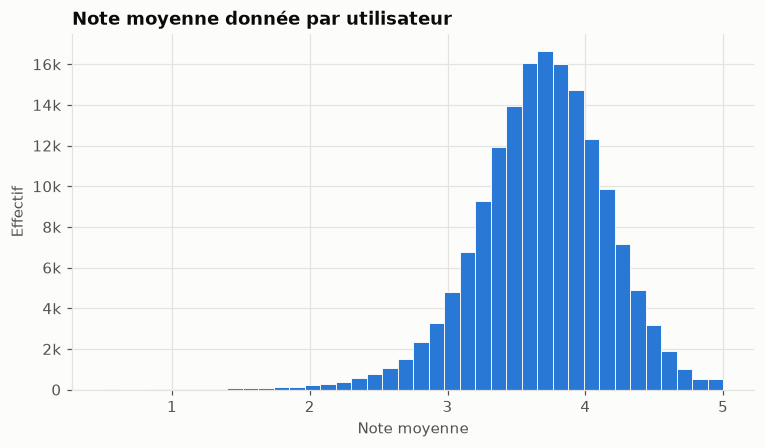

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
note moyenne par utilisateur,"162,541.000",3.679,0.477,0.500,2.339,2.879,3.399,3.700,4.000,4.409,4.707,5.000


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
écart-type des notes par utilisateur,"162,541.000",0.929,0.261,0.000,0.398,0.542,0.752,0.908,1.085,1.387,1.649,2.308


In [13]:
show(plots.plot_distribution(users["mean_rating"], "Note moyenne donnée par utilisateur", "Note moyenne"))
display(eda.describe_counts(users["mean_rating"]).to_frame("note moyenne par utilisateur").T)
display(eda.describe_counts(users["std_rating"]).to_frame("écart-type des notes par utilisateur").T)

In [14]:
display(eda.describe_counts(users["active_days"]).to_frame("jours entre 1re et dernière note").T)
one_day = (users["active_days"] == 0).mean()
print(f"Utilisateurs dont toutes les notes tiennent en moins de 24 h : {one_day:.1%}")

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
jours entre 1re et dernière note,"162,541.000",221.185,716.473,0.000,0.000,0.000,0.000,0.000,40.000,"1,334.000","3,938.800","8,101.000"


Utilisateurs dont toutes les notes tiennent en moins de 24 h : 60.4%


## 6. Popularité des films et longue traîne

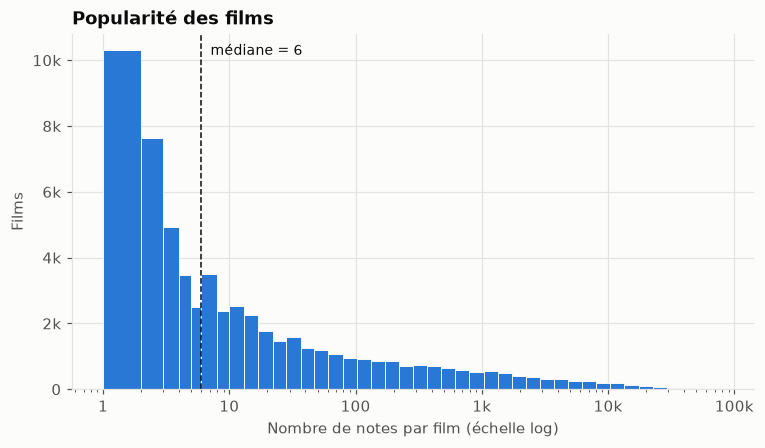

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
notes par film,"59,047.000",423.393,"2,477.886",1.000,1.000,1.000,2.000,6.000,36.000,"1,503.400","9,941.620","81,491.000"


In [15]:
popularity = stats["popularity"]
show(plots.plot_count_histogram(popularity["n_ratings"], "film", "Popularité des films"))
eda.describe_counts(popularity["n_ratings"]).to_frame("notes par film").T

Films ayant au plus n notes :


,max_ratings,n_entities,share_entities,share_ratings
0,1,10298,0.174,0.000
1,5,28840,0.488,0.003
2,10,35690,0.604,0.005
3,20,40917,0.693,0.008
4,50,45960,0.778,0.014
5,100,48756,0.826,0.022


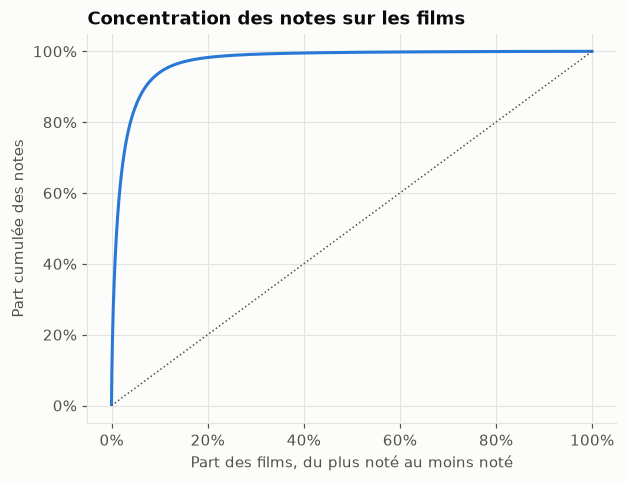

,top_share,n_entities,share_ratings
0,0.010,590,0.476
1,0.050,2952,0.845
2,0.100,5905,0.940
3,0.200,11809,0.983


In [16]:
print("Films ayant au plus n notes :")
display(stats["movie_low"])
show(plots.plot_lorenz(popularity["n_ratings"], "film"))
stats["movie_concentration"]

In [17]:
stats["top_movies"]

,title,n_ratings,mean_rating
0,Forrest Gump (1994),81491,4.048
1,"Shawshank Redemption, The (1994)",81482,4.414
2,Pulp Fiction (1994),79672,4.189
3,"Silence of the Lambs, The (1991)",74127,4.151
4,"Matrix, The (1999)",72674,4.154
5,Star Wars: Episode IV - A New Hope (1977),68717,4.120
6,Jurassic Park (1993),64144,3.679
7,Schindler's List (1993),60411,4.248
8,Braveheart (1995),59184,4.002
9,Fight Club (1999),58773,4.228


La note moyenne d'un film peu noté est peu fiable : on le vérifie en comparant la dispersion
des moyennes selon le nombre de notes.

In [18]:
bins = [0, 1, 5, 20, 100, 1000, popularity["n_ratings"].max()]
popularity.assign(tranche=pd.cut(popularity["n_ratings"], bins=bins)).groupby(
    "tranche", observed=True
)["mean_rating"].agg(["count", "mean", "std", "min", "max"])

,count,mean,std,min,max
tranche,,,,,
"(0, 1]",10298,2.950,1.127,0.500,5.000
"(1, 5]",18542,2.987,0.753,0.500,5.000
"(5, 20]",12077,3.050,0.555,0.500,4.500
"(20, 100]",7839,3.156,0.452,0.855,4.278
"(100, 1000]",6501,3.247,0.498,0.899,4.327
"(1000, 81491]",3790,3.404,0.470,1.457,4.483


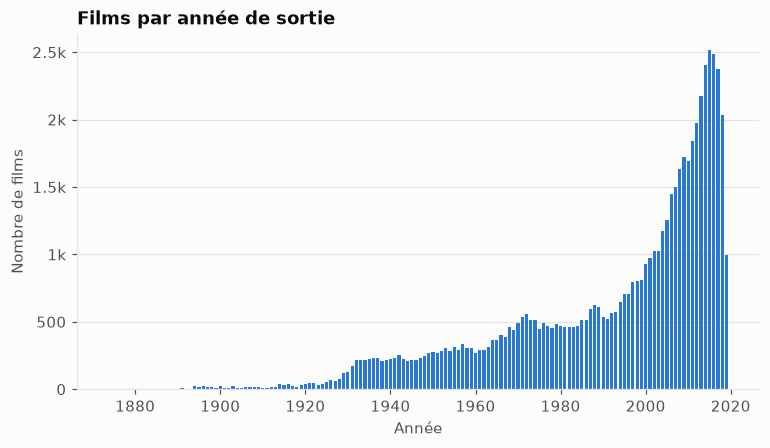

In [19]:
show(plots.plot_yearly(stats["release_years"], "n_movies", "Films par année de sortie", "Nombre de films"))

## 7. Genres

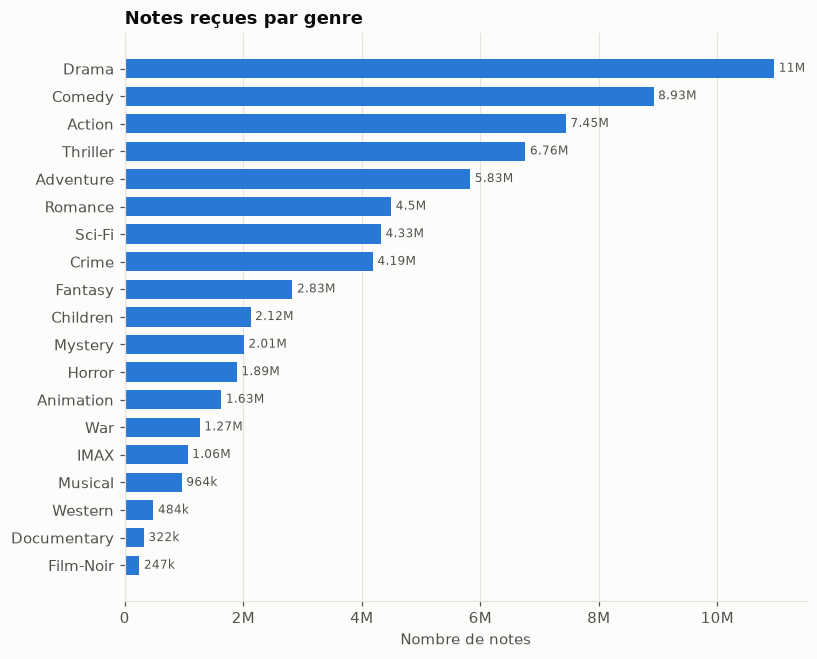

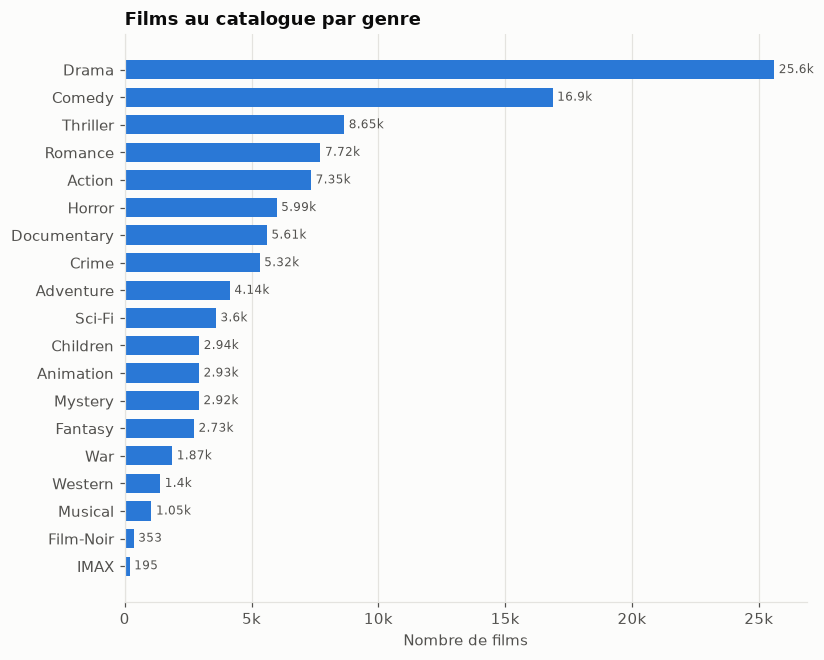

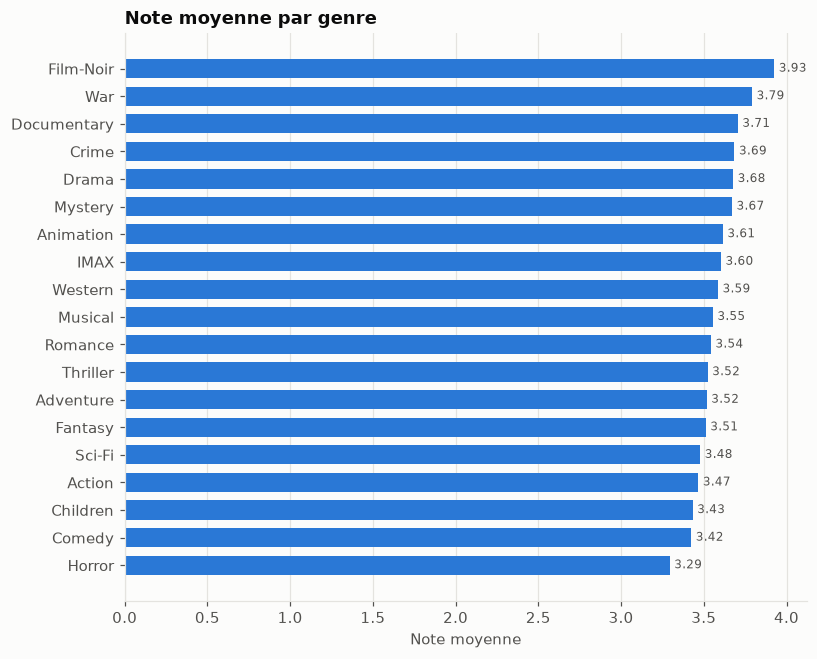

,genre,n_movies,n_ratings,mean_rating
0,Drama,25606,10962833,3.677
1,Comedy,16870,8926230,3.424
2,Action,7348,7446918,3.467
3,Thriller,8654,6763272,3.523
4,Adventure,4145,5832424,3.517
5,Romance,7719,4497291,3.543
6,Sci-Fi,3595,4325740,3.478
7,Crime,5319,4190259,3.685
8,Fantasy,2731,2831585,3.512
9,Children,2935,2124258,3.433


In [20]:
genres = stats["genres"]
show(plots.plot_horizontal_bars(genres, "genre", "n_ratings", "Notes reçues par genre", "Nombre de notes"))
show(plots.plot_horizontal_bars(genres, "genre", "n_movies", "Films au catalogue par genre", "Nombre de films"))
show(plots.plot_horizontal_bars(genres, "genre", "mean_rating", "Note moyenne par genre", "Note moyenne", fmt="float"))
genres

In [21]:
tables["movies"]["n_genres"].value_counts().sort_index().rename("films").to_frame().T

n_genres,0,1,2,3,4,5,6,7,8,10
films,5062,25569,18326,9852,2784,680,123,24,2,1


## 8. Dimension temporelle

Les horodatages couvrent-ils une période suffisante pour une séparation temporelle
entraînement / test ?

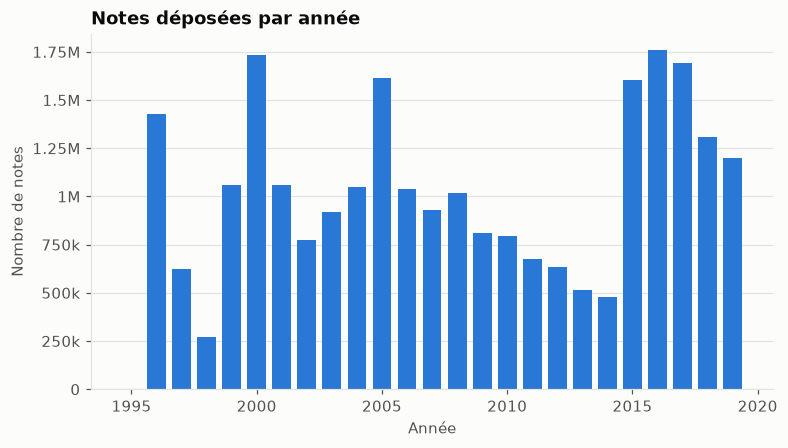

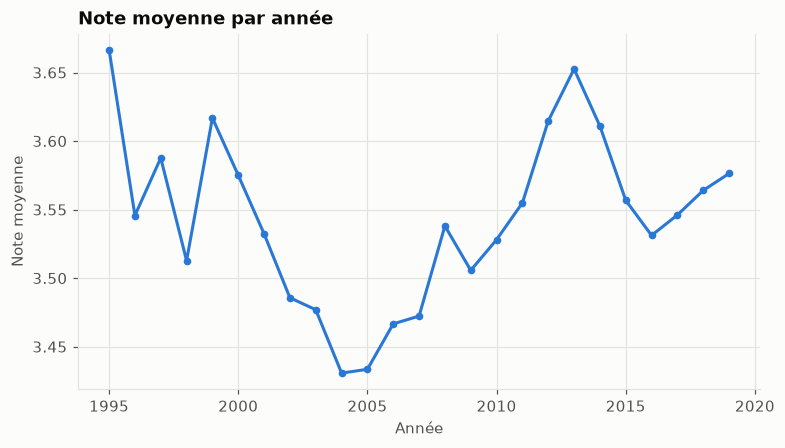

,year,n_ratings,mean_rating,active_users
0,1995,3,3.667,1
1,1996,1430093,3.546,23028
2,1997,626202,3.588,10014
3,1998,272099,3.513,3315
4,1999,1059080,3.617,8387
5,2000,1735398,3.575,13303
6,2001,1058750,3.532,9300
7,2002,776654,3.486,7098
8,2003,920295,3.477,7674
9,2004,1048116,3.431,7842


In [22]:
per_year = stats["per_year"]
show(plots.plot_yearly(per_year, "n_ratings", "Notes déposées par année", "Nombre de notes"))
show(plots.plot_yearly(per_year, "mean_rating", "Note moyenne par année", "Note moyenne", kind="line"))
per_year

In [23]:
ratings = tables["ratings"]
cutoffs = ratings["timestamp"].quantile([0.8, 0.9]).rename("date de coupure")
display(cutoffs.to_frame())
for q, cutoff in cutoffs.items():
    train_users = set(ratings.loc[ratings["timestamp"] <= cutoff, "userId"].unique())
    test = ratings[ratings["timestamp"] > cutoff]
    test_users = test["userId"].unique()
    known = sum(u in train_users for u in test_users)
    print(f"Coupure à {q:.0%} : {len(test):,} notes de test, {len(test_users):,} utilisateurs de test, "
          f"dont {known:,} ({known / len(test_users):.1%}) déjà vus à l'entraînement")

,date de coupure
0.800,2016-06-25 06:49:57.600+00:00
0.900,2018-01-04 02:45:00.800+00:00


Coupure à 80% : 5,000,019 notes de test, 31,059 utilisateurs de test, dont 6,401 (20.6%) déjà vus à l'entraînement


Coupure à 90% : 2,500,010 notes de test, 18,442 utilisateurs de test, dont 6,492 (35.2%) déjà vus à l'entraînement


## 9. Tags

In [24]:
display(pd.Series(stats["tag_stats"]).to_frame("valeur"))
stats["top_tags"]

,valeur
n_tag_applications,"1,093,333.000"
n_distinct_tags,"65,380.000"
n_tagging_users,"14,591.000"
n_tagged_movies,"45,251.000"
share_catalog_tagged,0.725


,tag,n_applications,n_movies
0,sci-fi,8795,558
1,atmospheric,7053,659
2,action,6783,978
3,comedy,6368,1624
4,surreal,5584,576
5,funny,5354,1165
6,based on a book,5196,1395
7,twist ending,4904,297
8,visually appealing,4691,346
9,romance,4482,1296


In [25]:
tags_per_movie = tables["tags"].groupby("movieId")["tag"].nunique()
eda.describe_counts(tags_per_movie).to_frame("tags distincts par film tagué").T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
tags distincts par film tagué,"45,251.000",10.242,16.463,1.000,1.000,1.000,2.000,5.000,11.000,38.000,79.000,707.000


## 10. Synthèse

Les constats chiffrés et leurs conséquences pour la modélisation sont consignés dans
`reports/data_report.md` (généré) et dans la section « Dataset » du `README.md`.